<h1>Import dataset and modules<h1>

In [ ]:
import sys, sklearn, ipykernel
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder
print(sys.version)
print(sys.executable)
print("Setup OK!")

print('test data cleaning')

print('hi')

# 1. Read the mapping file without skipping the blank rows between tables
IDS_mapping = pd.read_csv("IDs_mapping.csv", header=None,
                  names=["id", "description"], skip_blank_lines=False)

# 2. Split it into one dictionary per table
mappings = {}
current = None
for _, row in IDS_mapping.iterrows():
    if pd.isna(row["id"]):          # blank row: the next table starts
        current = None
    elif current is None:           # first row of a table = its name
        current = row["id"]
        mappings[current] = {}
    else:                           # normal row: code -> description
        mappings[current][int(row["id"])] = row["description"]

# 3. Replace the codes in the patient data with their descriptions
df = pd.read_csv("diabetic_data.csv", na_values=['?'])
for col, mapping in mappings.items():
    df[col] = df[col].map(mapping)


/var/folders/wy/ymq6dx6n0z76tgh43whw2dxr0000gn/T/ipykernel_61365/3955573027.py:5: DtypeWarning: Columns (0: payer_code) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("diabetic_data.csv", na_values="?")


### Duplicates
Here we check the number of duplicates.

I found in encounter_id 0 duplicates, so each row contains its own encounter with a person at a hospital for some treatment.
In patient_nbr I found 71518 unique values, so there are 71518 unique persons in the database.
For the rest the duplicates seemed fine

In [ ]:
dup_counts = df.apply(lambda col: col.duplicated().sum())

# Missing values per column (count and percentage)
missing_counts = df.isnull().sum()
missing_pct = (missing_counts / len(df) * 100).round(2)

# Put it all in one table
summary = pd.DataFrame({
    "n_unique": df.nunique(),
    "n_duplicates": dup_counts,
    "n_missing": missing_counts,
    "pct_missing": missing_pct
}).sort_values("n_missing", ascending=False)

print(summary.to_string())

print(df.shape)

### Missing values

Here we check the missing and possible missing values in the dataset.
- Race has 2273 NaN and 1506 Other.
- Gender has 3 Unknown/Invalid values, which are not noted as missing values in python here.
- Weight has 98569 (96,8%) values, so should be dropped!
- Payer_code has 40256 (39,5%) NaN values
- medical_specialty has 49949 NaN values which is 49,1% of the dataset.
    - However the names should be checked, which are not good and which should be combined with an umbrella specialty like the two separate ones 'Orthopedics' and 'Orthopedics-Reconstructive'. Domain knowledge should be applied here.
- diag_1 has 21 missing values (0.02%)
- diag_2 has 358 missing values (0.35%)
- diag_3 has 1423 missing values (1.40%)
- max_glu_serum has 96420 (94.75%) missing values
- A1Cresult has 84748 (83.28%) missing values.
- Examide, citoglipton no missing values, glimepiride-pioglitazone, metformin-rosiglitazone, metformin-pioglitazone but only contains no.

All other columns do not contain missing values, '?' or other weird values


In [ ]:
df = pd.read_csv("diabetic_data.csv", na_values="?")

pd.set_option("display.max_rows", None)   # show all rows, no "..."

cols_with_missing = df.columns

for col in cols_with_missing:
    print(f"\n=== {col} ({df[col].nunique()} unique values) ===")
    print(df[col].value_counts(dropna=False))

cols = ["diag_1", "diag_2", "diag_3"]
missing = df[cols].isnull().sum()
percent = (missing / len(df) * 100).round(2)

print(pd.DataFrame({"missing": missing, "percent": percent}))

print(df.shape)

The code below shows that encounter_id and patient_nbr have only numeral values.

In [ ]:
for col in ["encounter_id", "patient_nbr"]:
    values = df[col].astype(str).str.strip()
    non_numeric = df[pd.to_numeric(df[col], errors="coerce").isna()]
    
    print(f"{col}: {len(non_numeric)} non-numeric rows")
    if len(non_numeric) > 0:
        print(non_numeric[[col]].head(20))

    lengths = df[col].astype(str).str.len()
    counts = lengths[lengths <= 4].value_counts().sort_index()

    print(f"\n{col}:")
    for length in range(1, 5):
        print(f"  {length} digits: {counts.get(length, 0)}")

In [ ]:
#Nateglinide
print(df['nateglinide'].value_counts(normalize= True))

#chlorpropamide
print(df['chlorpropamide'].value_counts(normalize=True)) #>99.9

#acetohexamide
print(df['acetohexamide'].value_counts(normalize=True)) #>99.9

#tolbutamide
print(df['tolbutamide'].value_counts(normalize=True)) #>99.9

#acarbose
print(df['acarbose'].value_counts(normalize=True)) 

#miglitol
print(df['miglitol'].value_counts(normalize=True)) #>99.9

#troglitazone
print(df['troglitazone'].value_counts(normalize=True)) #99.9

#tolazamide
print(df['tolazamide'].value_counts(normalize=True)) #>99.9

#glyburide-metformin
print(df['glyburide-metformin'].value_counts(normalize=True))

#glipizide-metformin
print(df['glipizide-metformin'].value_counts(normalize=True)) #>99.9

#glimepiride-pioglitazone
print(df['glimepiride-pioglitazone'].value_counts(normalize=True)) #>99.9

#metformin-rosiglitazone
print(df['metformin-rosiglitazone'].value_counts(normalize=True)) #>99.9

#metformin-pioglitazone
print(df['metformin-pioglitazone'].value_counts(normalize=True)) #>99.9



<h1><u> Encoding </u></h1>
<h3>Encoding the 'gender', 'age' and 'admission_type_id'</h3>

<i>What is it for?</i> To turn text into numbers for the models to be able to work.





In [ ]:


df['gender'] = df['gender'].map({
    'Male': 0,
    'Female': 1
})


df['admission_type_id'] = df['admission_type_id'].replace({
    1: 'Emergency',
    2: 'Urgent',
    3: 'Elective',
    4: 'Newborn',
    5: 'unknown',
    6: 'unknown',
    8: 'unknown',
    7: 'Trauma Center'
})

<h3> admission_source_id encoding </h3>
The numbered values were changed into their description, so that one hot encoding could group them easily. Any value that did not have a count of over 100 went into the other category.

In [ ]:
print(df['admission_source_id'].unique())
print(df['admission_source_id'].value_counts)

df['admission_source_id'] = df['admission_source_id'].replace({
    1: 'Physician Referral',
    2: 'Clinic Referral',
    3: 'HMO Referral',
    4: 'Transfer from a hospital',
    5: 'Transfer from a Skilled Nursing Facility (SNF)',
    6: 'Transfer from another health care facility',
    7: 'Emergency Room',
    8: 'other',
    9: 'unknown',
    10: 'other',
    11: 'other',
    12: 'Premature Delivery',
    13: 'other',
    14: 'other',
    15: 'unknown',
    16: 'unknown',
    17: 'unknown',
    18: 'Transfer From Another Home Health Agency',
    19: 'Readmission to Same Home Health Agency',
    20: 'unknown',
    21: 'unknown',
    22: 'other',
    23: 'Born inside this hopsital',
    24: 'Born outside this hospital',
    25: 'other',
    26: 'Transfer from Hospice'

})

<h3>Encoding medical_specialty</h3>

In [ ]:
print(df['medical_specialty'].unique())
print(df['medical_specialty'].value_counts)

df['medical_specialty'] = df['medical_specialty'].fillna('unknown')
df['medical_specialty'] = df['medical_specialty'].replace({
    'Surgery-General': 'surgery',
    'Surgery-Cardiovascular/Thoracic': 'surgery',
    'Surgery-Neuro': 'surgery',
    'Surgery-Colon&Rectal': 'surgery',
    'Surgery-Thoracic': 'surgery',
    'Surgery-Vascular': 'surgery',
    'Surgery-Plastic': 'surgery',
    'Surgery-Cardiovascular': 'surgery',
    'Surgery-Maxillofacial': 'surgery',
    'Surgery-Pediatric': 'surgery',
    'Surgery-PlasticwithinHeadandNeck': 'surgery'
})


In [ ]:
categorical_columns = ['age', 'admission_type_id', 'admission_source_id']
diabetic_data_encoded = pd.get_dummies(
    df,
    columns = categorical_columns,
    dtype=int,
    drop_first=True
)
print(diabetic_data_encoded.head())

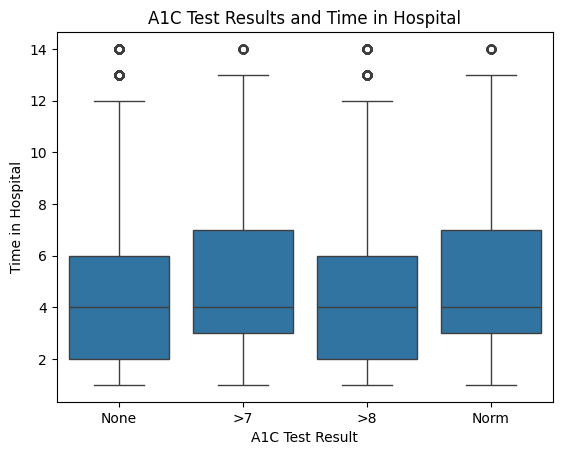

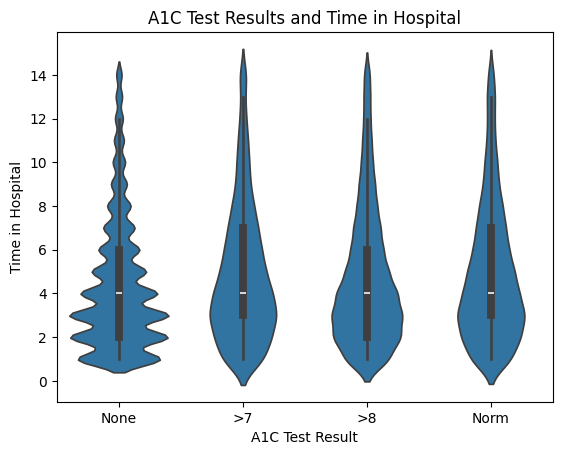

In [ ]:
#Generating a plot for A1C tests and time in hospital
sns.boxplot(data=df, x='A1Cresult', y='time_in_hospital')
plt.title('A1C Test Results and Time in Hospital')
plt.xlabel('A1C Test Result')
plt.ylabel('Time in Hospital')

#Generating a violin plot
plt.figure()
sns.violinplot(data=df, x='A1Cresult', y='time_in_hospital')
plt.title('A1C Test Results and Time in Hospital')
plt.xlabel('A1C Test Result')
plt.ylabel('Time in Hospital')
plt.show()

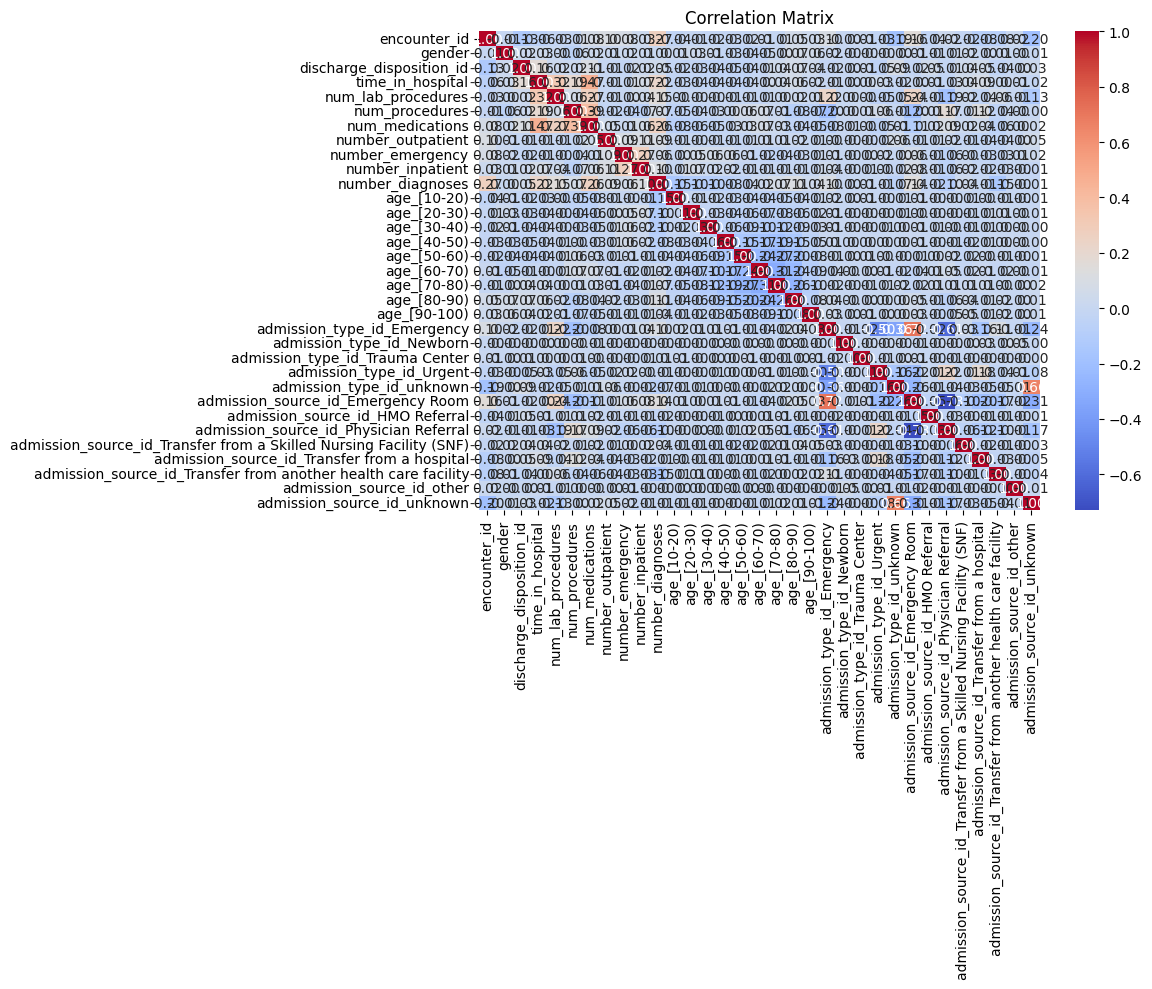

In [ ]:
#Correlation Matrix
plt.figure(figsize=(12,10))
numeric_data = df.select_dtypes(include='number').drop(columns='patient_nbr', errors='ignore')
correlation_matrix = numeric_data.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix')
plt.tight_layout()
plt.savefig('correlation_matrix.png')


<h2>Grouping the diag_1 variable and dropping diag_2, diag_3 and number_diagnoses<h2>

As the diag_1 shows the primary diagnosis accredited for the stay of the patient, we assume this diagnosis is placed during the admission of the patient to the hospital. In this way this would be data that would be avaivable to the scheduling office at the hospital when the patient is addmited.

Doing this also helps simplify the model, so it does not overfit.

In [3]:
# Defines the buckets for the diag_1 values
d1_bucket_def = {
    1: "Infectious and Parasitic Diseases",
    140: "Neoplasms",
    240: "Endocrine, Nutritional and Metabolic Diseases, and Immunity Disorders",
    280: "Diseases of the Blood and Blood-forming Organs",
    290: "Mental Disorders",
    320: "Diseases of the Nervous System and Sense Organs",
    390: "Diseases of the Circulatory System",
    460: "Diseases of the Respiratory System",
    520: "Diseases of the Digestive System",
    580: "Diseases of the Genitourinary System",
    630: "Complications of Pregnancy, Childbirth, and the Puerperium",
    680: "Diseases of the Skin and Subcutaneous Tissue",
    710: "Diseases of the Musculoskeletal System and Connective Tissue",
    740: "Congenital Anomalies",
    760: "Certain Conditions Originating in the Perinatal Period",
    780: "Symptoms, Signs, and Ill-defined Conditions",
    800: "Injury and Poisoning",
}

# Extracts and converts the variable data into a string, drops white spaces and upparcases all letters
codes = df["diag_1"].astype("string").str.strip().str.upper()

# Extract the numeric value before the dot using a regex. An "8" is seen as "008". Requires digits as an input and gives missing values if it gets a letters or symbols a part form "."
numeric_category = pd.to_numeric(
    codes.str.extract(r"^([0-9]{1,3})(?:\.[0-9]+)?$", expand=False),
    errors="coerce",
)

# assigns a new column to df, by comparing the extracted number to the buckets, and then outputing the name of the bucket
df["diag_1_category"] = pd.cut(
    numeric_category,
    bins=[*d1_bucket_def, 1000],
    labels=list(d1_bucket_def.values()),
    right=False,
).astype("string")

# Assign the supplementary codes by prefix.
df.loc[codes.str.startswith("E", na=False), "diag_1_category"] = (
    "External Causes of Injury and Poisoning"
)
df.loc[codes.str.startswith("V", na=False), "diag_1_category"] = (
    "Factors Influencing Health Status and Contact with Health Services"
)

print(df["diag_1_category"].value_counts(dropna=False))

#overwrites the old diag_1 values
df['diag_1'] = df["diag_1_category"]


diag_1_category
Diseases of the Circulatory System                                       30336
Endocrine, Nutritional and Metabolic Diseases, and Immunity Disorders    11459
Diseases of the Respiratory System                                       10407
Diseases of the Digestive System                                          9208
Symptoms, Signs, and Ill-defined Conditions                               7636
Injury and Poisoning                                                      6974
Diseases of the Genitourinary System                                      5078
Diseases of the Musculoskeletal System and Connective Tissue              4957
Neoplasms                                                                 3433
Infectious and Parasitic Diseases                                         2768
Diseases of the Skin and Subcutaneous Tissue                              2530
Mental Disorders                                                          2262
Factors Influencing Health Status an

The variable now contains 19 distinct values one of which is NA, the others are descriptors of categories of diagnosies.

We drop diag_2, diag_3 and number_diagnoses because we cannot assume at what point these diagnosis were placed, thus this data might not be avaibale at the time of the model's real world use.

In [4]:
df = df.drop(columns = ['diag_2','diag_3','number_diagnoses'])

Rename the diag_1 column

In [5]:
df = df.rename(columns={'diag_1' : 'diag_cat'})

### Merging of categories within variables
Here I will merge the smallest categories together so that the data will be more balanced.

The resulting variables are called:
- `age` → `age_grouped`
- `admission_source_id` → `admission_source_grouped`
- `admission_type_id` → `admission_type_grouped`

As is visible in the graphs, admission_source_grouped and admission_type_grouped have missing values called `Unknown`, although it is not noted in the dataset as missing values

In [ ]:
# Age groups
age_groups = {
    "[0-10)": "<40", "[10-20)": "<40", "[20-30)": "<40",
    "[30-40)": "<40", "[40-50)": "40-50", "[50-60)": "50-60",
    "[60-70)": "60-70", "[70-80)": "70-80",
    "[80-90)": "80+", "[90-100)": "80+",
}
df["age_grouped"] = df["age"].map(age_groups)

# Plot, sorted by age
order = ["<40", "40-50", "50-60", "60-70", "70-80", "80+"]
sns.countplot(data=df, x="age_grouped", order=order)
plt.title("Age grouped")
plt.show()

# Admission source
source_groups = {
    "Emergency Room": "Emergency Room",
    "Physician Referral": "Physician Referral",
    "Transfer from a hospital": "Other",
    "Transfer from another health care facility": "Other",
    "Clinic Referral": "Other",
    "Transfer from a Skilled Nursing Facility (SNF)": "Other",
    "HMO Referral": "Other",
    "Court/Law Enforcement": "Other",
    "Transfer from hospital inpt/same fac reslt in a sep claim": "Other",
    "Transfer from critial access hospital": "Other",
    "Extramural Birth": "Other",
    "Normal Delivery": "Other",
    "Transfer from Ambulatory Surgery Center": "Other",
    "Sick Baby": "Other",
    "Premature Delivery": "Other",
    "Transfer From Another Home Health Agency": "Other",
    "Readmission to Same Home Health Agency": "Other",
    "Born inside this hospital": "Other",
    "Born outside this hospital": "Other",
    "Transfer from Hospice": "Other",
    "Not Mapped": "Unknown",
    "Not Available": "Unknown",
    "Unknown/Invalid": "Unknown",
    "NULL": "Unknown",
}
source_groups.update({" " + key: value for key, value in source_groups.items()})

df["admission_source_grouped"] = (
    df["admission_source_id"].map(source_groups).fillna("Unknown")
)

order = ["Emergency Room", "Physician Referral", "Other", "Unknown"]
sns.countplot(data=df, x="admission_source_grouped", order=order)
plt.title("Admission source")
plt.show()

# Admission type
type_groups = {
    "Emergency": "Emergency",
    "Elective": "Elective",
    "Urgent": "Urgent",
    "Trauma Center": "Other",
    "Newborn": "Other",
    "Not Available": "Unknown",
    "Not Mapped": "Unknown",
}
type_groups.update({" " + key: value for key, value in source_groups.items()})

df["admission_type_grouped"] = df["admission_type_id"].map(type_groups).fillna("Unknown")

order = ["Emergency", "Elective", "Urgent", "Other", "Unknown"]
sns.countplot(data=df, x="admission_type_grouped", order=order)
plt.title("Admission type")
plt.show()

# Visuals of univariate plots

Here we see that there is an outlier of 0 with num_lab_procedures, but that the variable is normally distributed

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

cols = ['race', 'gender', 'age', 'admission_type_id', 'discharge_disposition_id',
        'admission_source_id', 'payer_code', 'num_lab_procedures',
        'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide',
        'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide',
        'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone',
        'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin',
        'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone',
        'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted']

for col in cols:
    if col == 'admission_type_id' or col == 'admission_source_id':
        plt.figure(figsize=(12, 10))
    else: 
        plt.figure(figsize=(10, 5))
    if col == 'num_lab_procedures':
        sns.histplot(df["num_lab_procedures"], bins=30)
        plt.xlabel("Number of lab procedures")
        plt.ylabel("Number of encounters")
        plt.show()
    else:
        sns.countplot(data=df, x=col, order=df[col].value_counts().index)
        plt.title(col)
        plt.xlabel('')
        plt.xticks(rotation=90)
        plt.tight_layout()
        plt.show()


### Bivariate plots